# Parts 2 and 3

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

yournetid = 'ltipto11'

df = pd.read_csv(yournetid + '_project_summary.csv', sep=';', low_memory=False)
df.columns = ['project', 'commit', 'author', 'time', 'message']
df['time'] = pd.to_numeric(df['time'], errors='coerce')
df['Month'] = pd.to_datetime(df['time'], unit='s').dt.strftime('%Y-%m')
projects = sorted(df['project'].unique())
df.head()

,project,commit,author,time,message,Month
0,rafavzqz_geopdes,00096a8185cf670b800e75343f26413990d42303,rafavzqz <rafavzqz@de73d896-90e3-4c87-98df-839...,1309533879,The examples in the article with the new version,2011-07
1,rafavzqz_geopdes,00127306e06e39ecd0c0614a0337fe249f5d6041,cdf <cdf@de73d896-90e3-4c87-98df-8390668dc151>,1294670579,stream function formulation finally works,2011-01
2,rafavzqz_geopdes,0020ef4ab6245d64cafc3594452460aa043df21b,vazquez <vazquez@imati.cnr.it>,1617985169,Merge branch 'multipatch_C1' of github.com:raf...,2021-04
3,rafavzqz_geopdes,002e6cf594c43c3ad2b02e0c2bfa6a214b6bbdbb,vazquez <vazquez@imati.cnr.it>,1447175722,Working on multipatch classes. The boundary is...,2015-11
4,rafavzqz_geopdes,003a1fd9a3f316f9446c64b6aa077488a3459781,vazquez <vazquez@imati.cnr.it>,1447351824,Work on weak BC for RT\n,2015-11


## Part 2: Monthly time series

In [2]:
def monthly_series(prj):
    counts = df[df['project'] == prj].groupby('Month').size()
    counts.index = pd.PeriodIndex(counts.index, freq='M')
    full = pd.period_range(counts.index.min(), counts.index.max(), freq='M')
    counts = counts.reindex(full, fill_value=0)
    return pd.DataFrame({'Month': counts.index.strftime('%Y-%m'), '#Commits': counts.values})

series = {}
for prj in projects:
    ts = monthly_series(prj)
    series[prj] = ts
    ts.to_csv(f'{yournetid}_commits_timeseries_{prj}.csv', sep=';', index=False)
    print(f'{prj}: {len(ts)} months, {ts["#Commits"].sum()} commits')

cambridgemolecularengineering_tabledataextractor: 78 months, 318 commits
llnl_zfp: 122 months, 2038 commits
mantidproject_mantid: 229 months, 176744 commits
mic-dkfz_nnunet: 80 months, 2575 commits
ofloveandhate_paramotopy: 175 months, 902 commits
qiskit_openqasm: 106 months, 2033 commits
qzhu2017_pyxtal: 92 months, 2317 commits
r-spatial_gstat: 124 months, 538 commits
rafavzqz_geopdes: 173 months, 2582 commits
ros-perception_slam_gmapping: 182 months, 316 commits


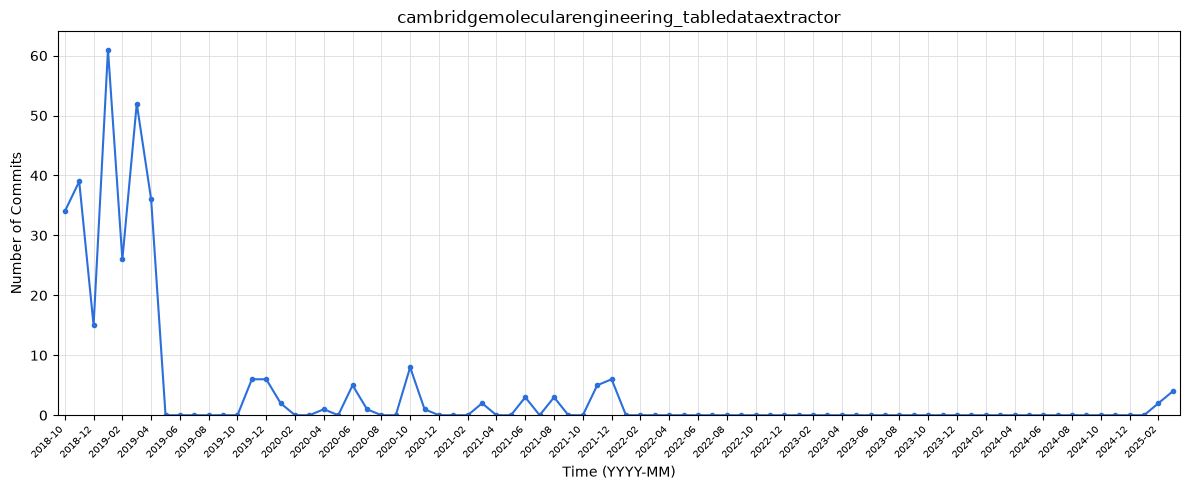

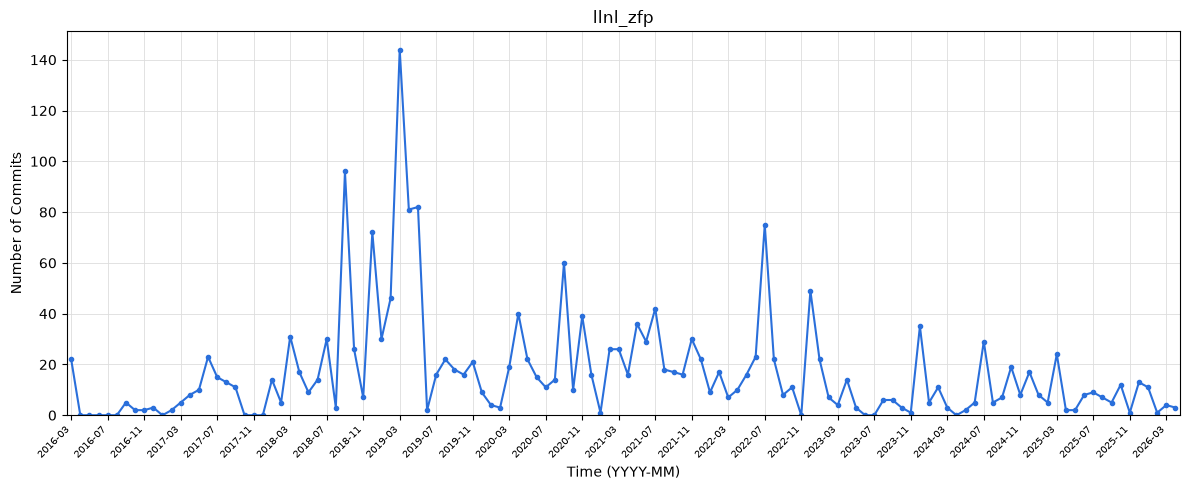

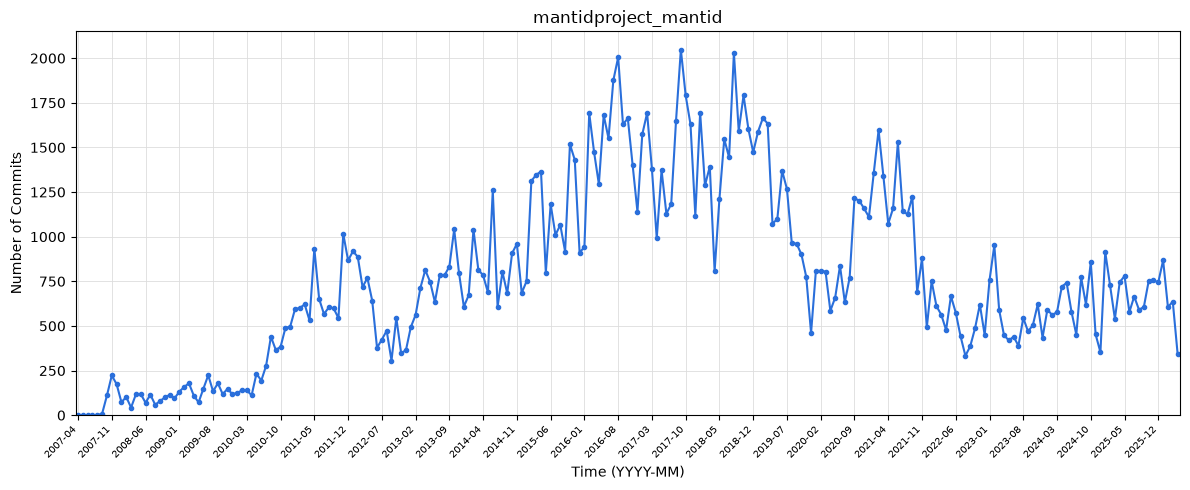

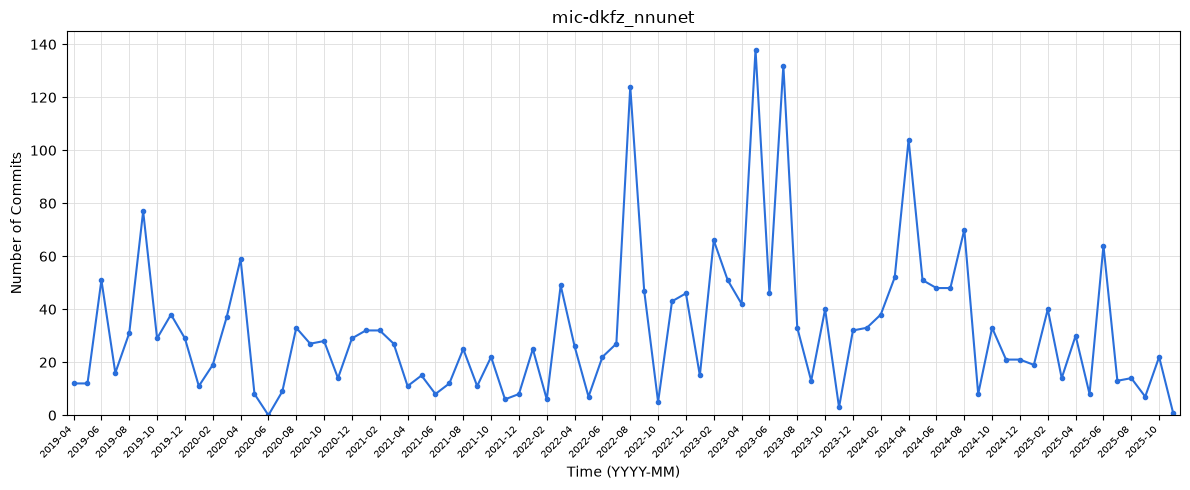

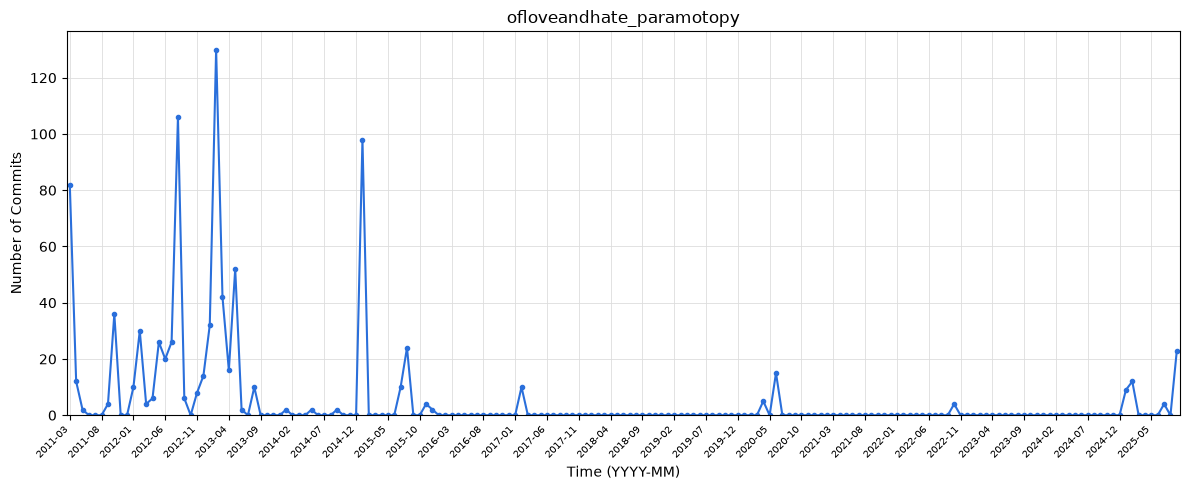

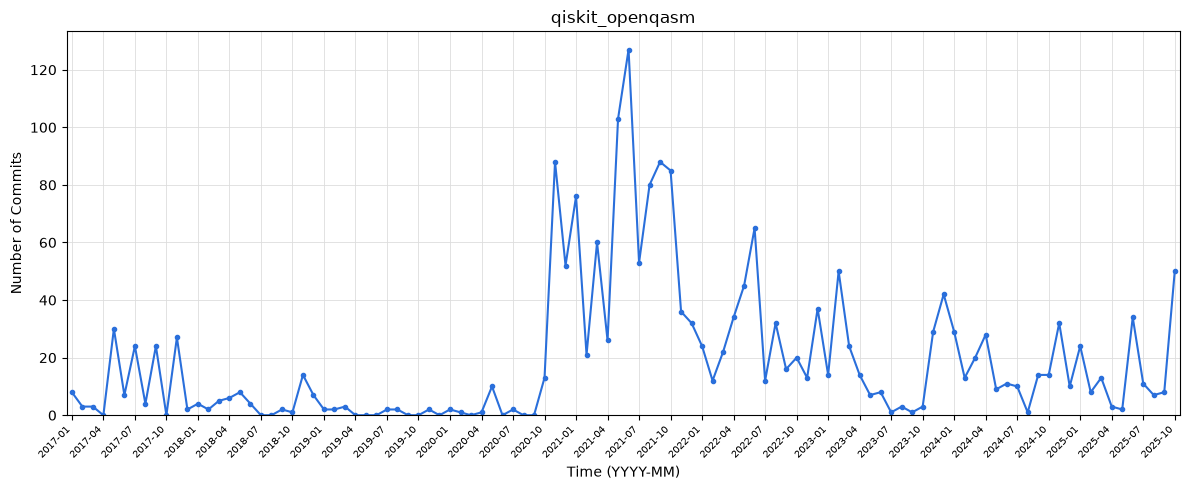

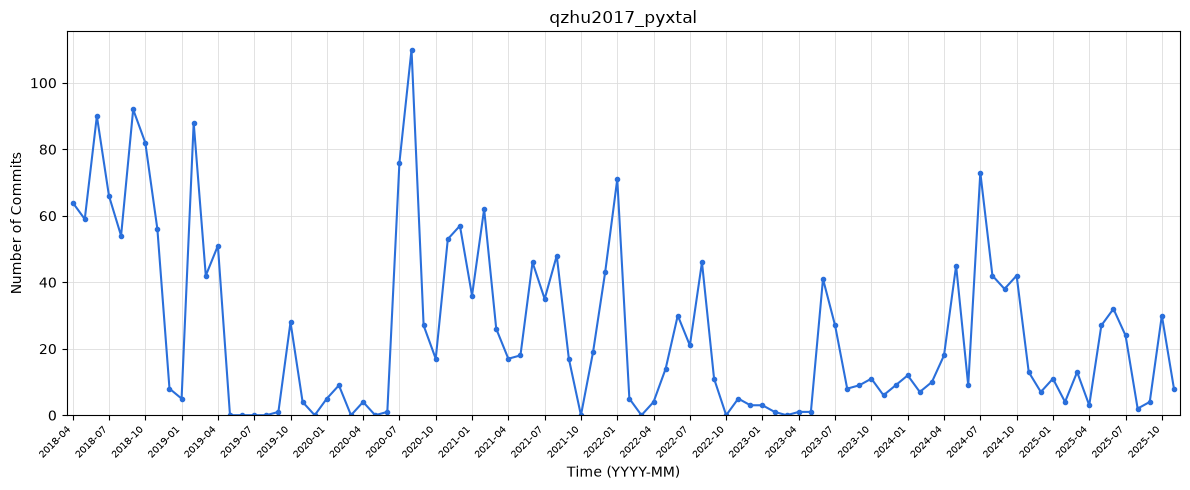

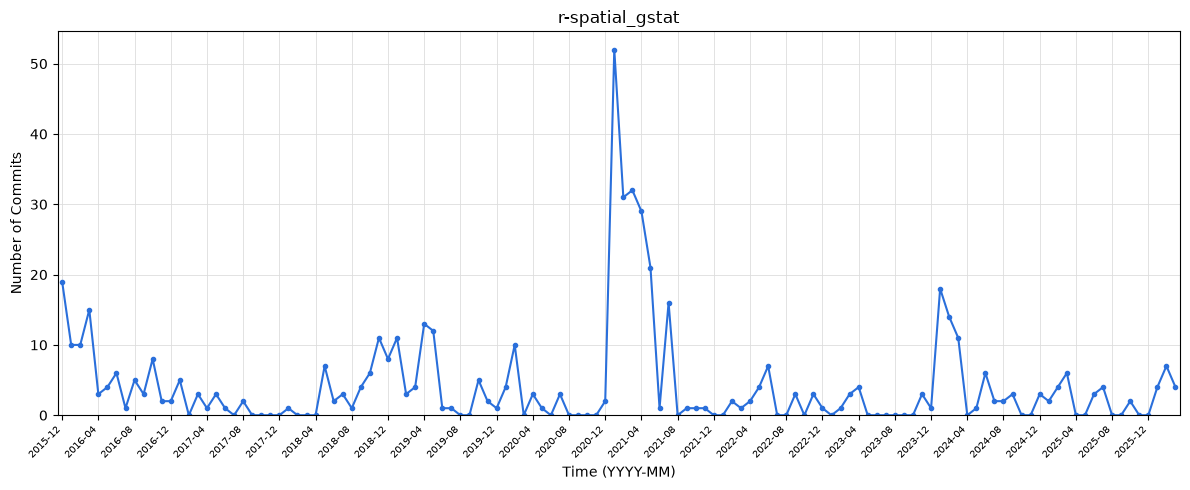

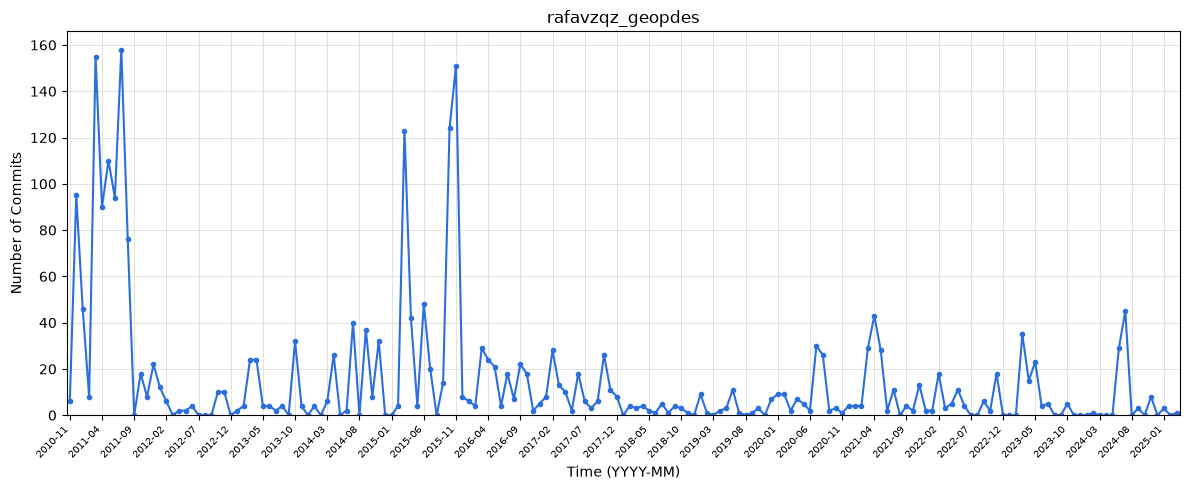

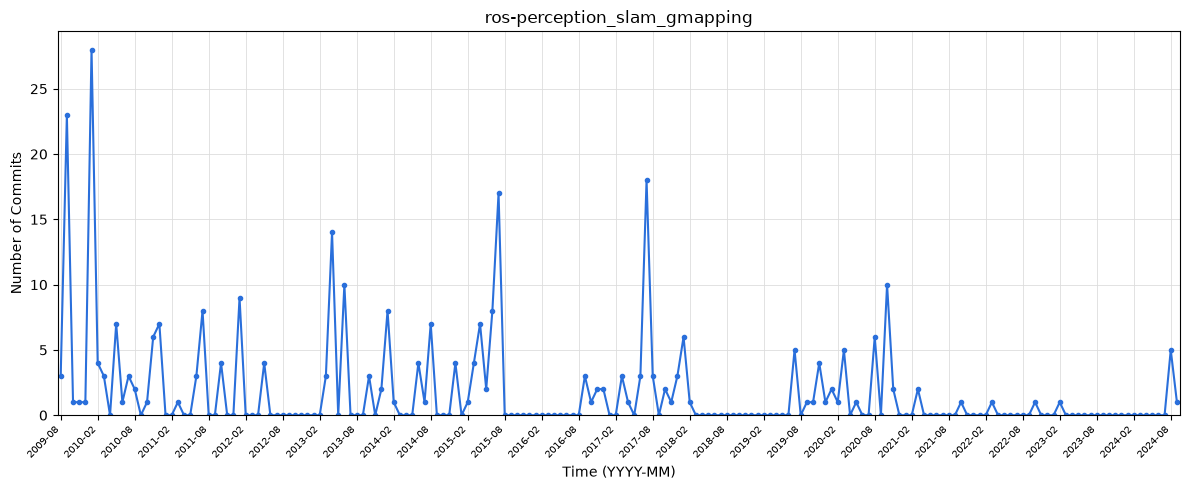

In [3]:
for prj in projects:
    ts = series[prj]
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(ts['Month'], ts['#Commits'], marker='o', markersize=3,
            linestyle='-', linewidth=1.5, color='#2a6fdb')
    ax.set_xlabel('Time (YYYY-MM)')
    ax.set_ylabel('Number of Commits')
    ax.set_title(prj)
    ax.grid(True, color='#dddddd', linewidth=0.6)
    ax.set_axisbelow(True)
    # only show about 30 month labels so the long projects are still readable
    step = max(1, len(ts) // 30)
    ax.set_xticks(range(0, len(ts), step))
    ax.set_xticklabels(ts['Month'][::step], rotation=45, ha='right', fontsize=7)
    ax.set_xlim(-0.5, len(ts) - 0.5)
    ax.set_ylim(bottom=0)
    fig.tight_layout()
    fig.savefig(f'{yournetid}_timeseries_{prj}.png', dpi=300)
    plt.show()
    plt.close(fig)

## Identify the longest inactivity gap

In [4]:
def zero_runs(ts):
    runs, start = [], None
    for i, c in enumerate(ts['#Commits']):
        if c == 0 and start is None:
            start = i
        elif c != 0 and start is not None:
            runs.append((start, i - 1))
            start = None
    if start is not None:
        runs.append((start, len(ts) - 1))
    return runs

gap_rows = []
for prj in projects:
    ts = series[prj]
    runs = zero_runs(ts)
    best = None
    for s, e in runs:
        if best is None or (e - s) > (best[1] - best[0]):
            best = (s, e)
    s, e = best
    gap_end = ts['Month'][e]
    gap_rows.append({
        'Project': prj,
        'LongestGapStart': ts['Month'][s],
        'LongestGapEnd': gap_end,
        'LongestGapLength': e - s + 1,
        'NumCommitsAfterLastGap': int((df[df['project'] == prj]['Month'] > gap_end).sum()),
        'NumberOfGapsInTimeline': sum(1 for a, b in runs if b - a + 1 >= 3),
    })
gaps = pd.DataFrame(gap_rows)
gaps

,Project,LongestGapStart,LongestGapEnd,LongestGapLength,NumCommitsAfterLastGap,NumberOfGapsInTimeline
0,cambridgemolecularengineering_tabledataextractor,2022-01,2025-01,37,6,3
1,llnl_zfp,2016-04,2016-08,5,2016,2
2,mantidproject_mantid,2007-05,2007-08,4,176743,1
3,mic-dkfz_nnunet,2020-06,2020-06,1,2146,0
4,ofloveandhate_paramotopy,2017-03,2020-03,37,72,11
5,qiskit_openqasm,2019-04,2019-06,3,1841,1
6,qzhu2017_pyxtal,2019-05,2019-08,4,1560,1
7,r-spatial_gstat,2023-05,2023-10,6,100,4
8,rafavzqz_geopdes,2012-07,2012-09,3,1670,4
9,ros-perception_slam_gmapping,2023-03,2024-07,17,6,13


## Interpretation

this is the activity pattern for each project based on the plots above, and a gap here means 3 or more months in a row with no commits

| Project | Pattern | Gaps | Longest gap | Explanation |
|---|---|---|---|---|
| cambridgemolecularengineering_tabledataextractor | declining | 3 | 2022-01 to 2025-01 (37 mo) | most of the work (275 of 318 commits) was in late 2018 and 2019 while the tool and its paper were being made, then it dropped to about 18 commits a year in 2020 and 2021 and stopped for 3 years. There was a small burst of dependency fixes in Feb/Mar 2025 |
| llnl_zfp | rising then declining  | 2 | 2016-04 to 2016-08 (5 mo) | it went from 34 commits in 2016 up to 487 in 2019, stayed around 250 a year through 2022, then went down to about 100 a year from 2023. Both gaps are in the first two years before anyone was really using the GitHub repo |
| mantidproject_mantid | rising then declining  | 1 | 2007-05 to 2007-08 (4 mo) | it's a really big project, it grew to about 18k commits a year in 2016 to 2018 then dropped to around 6-8k a year from 2022. The only gap is the planning phase right after the repo was made in 2007, it jumps around a lot month to month but never stops for long |
| mic-dkfz_nnunet | steady | 0 | 2020-06 (1 mo) | it's been active nonstop since 2019 with about 200-600 commits a year and peaks in 2023/2024 around nnU-Net v2. The one empty month in June 2020 is too short to count as a gap |
| ofloveandhate_paramotopy | irregular | 11 | 2017-03 to 2020-03 (37 mo) | it was active 2011 to 2013, then only in random bursts (2015, Feb 2017, Apr/Jun 2020, Oct 2022, Jan to Sep 2025) with long breaks in between. Only one person has committed since 2016 |
| qiskit_openqasm | U-shaped | 1 | 2019-04 to 2019-06 (3 mo) | some activity at the start in 2017, then a low point in 2018/2019 (only 13 commits in 2019) while OpenQASM 2 was frozen, then a big jump to 787 commits in 2021 with OpenQASM 3, and it's stayed around 160-200 a year since |
| qzhu2017_pyxtal | irregular | 1 | 2019-05 to 2019-08 (4 mo) | a big spike when it started in 2018, then uneven bursts in 2020/2021 and 2024. There's one summer gap in 2019  |
| r-spatial_gstat | irregular | 4 | 2023-05 to 2023-10 (6 mo) | mostly low activity that follows CRAN releases, with one big burst in 2021 (185 commits) and smaller ones in 2016 and 2024. The 4-6 month quiet periods are in between releases |
| rafavzqz_geopdes | irregular | 4 | 2012-07 to 2012-09 (3 mo, the earliest of four tied 3 month gaps) | looks like a school project from one developer mostly with peaks in 2011 and 2015. All 4 gaps are exactly 3 months  |
| ros-perception_slam_gmapping | declining | 13 | 2023-03 to 2024-07 (17 mo) | low and declining like a lot of old ROS 1 packages, 62 commits in 2010 then mostly single digits after 2020 with lots of gaps |

## Part 3.1: Commits before and after the longest gap

In [5]:
gap_commit_rows = []
for _, g in gaps.iterrows():
    p = df[df['project'] == g['Project']].sort_values('time')
    pre = p[p['Month'] < g['LongestGapStart']].tail(10).copy()
    post = p[p['Month'] > g['LongestGapEnd']].head(10).copy()
    pre.insert(0, 'pre/post', 'pre')
    post.insert(0, 'pre/post', 'post')
    gap_commit_rows += [pre, post]

gap_commits = pd.concat(gap_commit_rows)[['pre/post', 'project', 'commit', 'author', 'time', 'message']]
gap_commits.columns = ['pre/post', 'project_wocid', 'commit_sha1', 'author', 'time', 'commit message']
gap_commits.to_csv(yournetid + '_project_gap_commits.csv', sep=';', index=False)
gap_commits.groupby(['project_wocid', 'pre/post'], sort=False).size()

project_wocid                                     pre/post
cambridgemolecularengineering_tabledataextractor  pre         10
                                                  post         6
llnl_zfp                                          pre         10
                                                  post        10
mantidproject_mantid                              pre          1
                                                  post        10
mic-dkfz_nnunet                                   pre         10
                                                  post        10
ofloveandhate_paramotopy                          pre         10
                                                  post        10
qiskit_openqasm                                   pre         10
                                                  post        10
qzhu2017_pyxtal                                   pre         10
                                                  post        10
r-spatial_gstat                

In [6]:
pd.set_option('display.max_colwidth', 90)
show = gap_commits.copy()
show['date'] = pd.to_datetime(show['time'], unit='s').dt.date
show['commit message'] = show['commit message'].astype(str).str.replace('\n', ' ').str[:90]
for prj, g in show.groupby('project_wocid', sort=False):
    print('=' * 20, prj)
    print(g[['pre/post', 'date', 'author', 'commit message']].to_string(index=False))

==================== cambridgemolecularengineering_tabledataextractor
pre/post       date                                                          author                                                                             commit message
     pre 2021-11-15                                      Taketomo <ti250@cam.ac.uk>                                                            Update Travis to check for 3.9 
     pre 2021-11-15                                      Taketomo <ti250@cam.ac.uk>                                                           Update requirement for requests 
     pre 2021-11-15                                      Taketomo <ti250@cam.ac.uk>                                                           Backwards compatibility changes 
     pre 2021-11-15             JurajMa <36662950+JurajMa@users.noreply.github.com> Merge pull request #48 from CambridgeMolecularEngineering/ti250/update-packages  Update pa
     pre 2021-12-17             JurajMa <36662950+Juraj

## Part 3.2: Themes, gap interpretation, and current status

In [7]:
github = pd.DataFrame([
    # project, stars, forks, last GitHub commit date (from part 1)
    ('rafavzqz_geopdes', 124, 51, '2025-03-11'),
    ('qiskit_openqasm', 1510, 361, '2026-07-27'),
    ('mantidproject_mantid', 240, 139, '2026-09-28'),
    ('mic-dkfz_nnunet', 8913, 2493, '2026-09-25'),
    ('cambridgemolecularengineering_tabledataextractor', 17, 4, '2025-03-14'),
    ('r-spatial_gstat', 215, 53, '2026-04-29'),
    ('llnl_zfp', 886, 182, '2026-09-23'),
    ('ros-perception_slam_gmapping', 736, 525, '2024-08-21'),
    ('ofloveandhate_paramotopy', 3, 1, '2025-09-30'),
    ('qzhu2017_pyxtal', 392, 83, '2026-09-09'),
], columns=['Project', 'nstars', 'nforks', 'lastGHCommitDate'])

github['Currentstatus'] = github['lastGHCommitDate'].apply(
    lambda d: 'Inactive' if d < '2025-04-01' else 'Active')
github

,Project,nstars,nforks,lastGHCommitDate,Currentstatus
0,rafavzqz_geopdes,124,51,2025-03-11,Inactive
1,qiskit_openqasm,1510,361,2026-07-27,Active
2,mantidproject_mantid,240,139,2026-09-28,Active
3,mic-dkfz_nnunet,8913,2493,2026-09-25,Active
4,cambridgemolecularengineering_tabledataextractor,17,4,2025-03-14,Inactive
5,r-spatial_gstat,215,53,2026-04-29,Active
6,llnl_zfp,886,182,2026-09-23,Active
7,ros-perception_slam_gmapping,736,525,2024-08-21,Inactive
8,ofloveandhate_paramotopy,3,1,2025-09-30,Active
9,qzhu2017_pyxtal,392,83,2026-09-09,Active


In [ ]:
annotations = {
 'cambridgemolecularengineering_tabledataextractor': dict(
    ActivityPattern='declining',
    BeforeThemes='Dependency updates:Other',
    AfterThemes='Dependency updates:Release',
    HypothesizedGapReason='The last PR before the gap came from a branch called jm2111_post_publication and was just "Minor clean-up", so the paper was out and the tool was basically done. The main author JurajMa never committed again, and an install issue from Nov 2021 is still open with no answer, so nobody was really watching the repo.',
    HasRecovered='only partial, there were 6 commits in Feb and Mar 2025',
    WhyRecovered='they updated versions and pinned numpy below 2.0, then bumped the version. It was probably numpy 2.0 breaking installs that brought them back.',
    WhoRecovered='a new person in the same Cambridge group (Dingyun Huang), then Taketomo Isazawa merged it and bumped the version',
    RecentThemes='Dependency updates:Release',
    Notes="it declined, 275 of the 318 commits came between Oct 2018 and Dec 2019 while the tool and its paper were being made. The longest gap is 37 months and happened because the paper was out and the tool was basically done. It's inactive, the last commit was on 2025-03-14 and nothing came after the dependency fix"),
 'llnl_zfp': dict(
    ActivityPattern='declining',
    BeforeThemes='Release:Documentation updates',
    AfterThemes='Feature development:Bug fixes',
    HypothesizedGapReason='The pre-gap commits are not development and are instead a bulk import on 2016-03-25 of some past tarball releases, that is LLNL opening a GitHub home for existing code. there were no issues or PRs from April to August 2016.',
    HasRecovered='yes',
    WhyRecovered='after a 5 month gap someone made an issue which was then solved and that revived the project acivity after the gap',
    WhoRecovered='someone named Pedro Melgueira',
    RecentThemes='Automated bot contributions:Bug fixes',
    Notes="it rose then declined after, going from 34 commits in 2016 to 487 in 2019, then back down to 100 a year in 2023. The longest gap was LLNL opening a GitHub home for existing code, and an issue from Pedro Melgueira revived it. it's active still, recent work is mostly Dependabot bumps and Windows/MinGW/Python 3.12 build fixes, not abandoned"),
 'mantidproject_mantid': dict(
    ActivityPattern='declining',
    BeforeThemes='Other:Other',
    AfterThemes='Feature development:Other',
    HypothesizedGapReason='this was easy to figure out because it\'s the planning phase not inactivity. The only commit before it was "Create initial directories" in April 2007, and the old tickets show they spent the summer on requirements docs, meeting minutes, and an architectural design doc.',
    HasRecovered='yes',
    WhyRecovered='coding started in Sept 2007 when Russell Taylor from ORNL committed the algorithm interface, algorithm factory, makefiles, and LoadRaw, all tied to the design tickets',
    WhoRecovered='a new person (Russell Taylor from ORNL) started the actual code after the planning team finished',
    RecentThemes='Automated bot contributions:Feature development',
    Notes="it rose then declined, it's huge with 176,744 commits from 530 authors. The only gap is 4 months in 2007 and it's the planning phase not inactivity. it's very active with commits every day in Oct 2026 getting ready for release 7.0"),
 'mic-dkfz_nnunet': dict(
    ActivityPattern='steady',
    BeforeThemes='Bug fixes:Feature development',
    AfterThemes='Bug fixes:Feature development',
    HypothesizedGapReason="N/A active Project. this isn't really a gap, commits stopped on 2020-05-28 and started again on 2020-07-06, but 25 issues were opened in June 2020 and 24 got closed by the end of July, so the maintainer was busy answering users instead of pushing code.",
    HasRecovered='N/A since it was never inactive',
    WhyRecovered='the commits right after fixed nnUNet_find_best_configuration and cleaned up ensembling, which is what people were asking about in the June issues',
    WhoRecovered='It was the same person the whole time (Fabian Isensee) with some outside contributors here and there',
    RecentThemes='Feature development:Bug fixes',
    Notes="it's steady and has had commits every month since April 2019 except one. There are 0 gaps of 3 months or more, the one empty month was when the maintainer was busy answering users instead of pushing code. it's very active with multiple commits a week in Sept and Oct 2026"),
 'ofloveandhate_paramotopy': dict(
    ActivityPattern='irregular',
    BeforeThemes='Other:Bug fixes',
    AfterThemes='Documentation updates:Other',
    HypothesizedGapReason='The last commits before it in Feb 2017 were wrap up stuff like fixes, gitignore cleanup, a version bump, and README changes. niemerg had already stopped in 2015 so it was one person, and they moved on to other things',
    HasRecovered='yes, it came back in stages',
    WhyRecovered="In 2020 the commits were mostly updating their new name in the manual and welcome screen, then a small cleanup in Oct 2022. Real work only came back in 2025 with matlab code and examples, switching the build to cmake, and fixing the old 2019 issues, plus a commit saying it's now syncing to an MPI gitlab",
    WhoRecovered='the same person',
    RecentThemes='Bug fixes:Documentation updates',
    Notes="it's irregular, it was active 2011 to 2013 and then only in bursts after that, with 11 gaps of 3 months or more. The longest gap was because it was one person and they moved on to other things, and it came back in stages from the same person. it's active, the last commit was 2025-09-30"),
 'qiskit_openqasm': dict(
    ActivityPattern='U-shaped',
    BeforeThemes='Automated bot contributions:Documentation updates',
    AfterThemes='Automated bot contributions:Bug fixes',
    HypothesizedGapReason='this one was kind of hard to figure out because in WoC the months around the gap look active, but most of those are auto generated PR merge commits for old PRs, not real work. The only real commits before the gap were README edits and I checked them, it was just renaming "Quantum Experience" to "IBM Q Experience" so it wasn\'t being archived',
    HasRecovered='yes',
    WhyRecovered='First there were small PRs in July and Aug 2019 then the some OpenQASM 3 work in 2020 and 2021 which moved the repo to its own openqasm org and brought in way more contributors',
    WhoRecovered='it recovered mostly with new people',
    RecentThemes='Documentation updates:Automated bot contributions',
    Notes="it's U-shaped, it went down to 13 commits in 2019 then jumped up to 787 in 2021 with OpenQASM 3. The gap was kind of hard to figure out because WoC shows auto generated PR merge commits, but the spec for OpenQASM 2 was basically frozen. it's active and the last commit was on 2026-07-27"),
 'qzhu2017_pyxtal': dict(
    ActivityPattern='irregular',
    BeforeThemes='Feature development:Bug fixes',
    AfterThemes='Documentation updates:Release',
    HypothesizedGapReason='Right before the gap, Scott Fredericks (the top committer in 2018 and 2019) did a bunch of features and fixes in April 2019 that closed the open bug issues, then nothing until late September and no new issues either',
    HasRecovered='yes',
    WhyRecovered='the project lead brought it back in Oct 2019 with a bunch of documentation and release prep commits like "add doc to prepare for release" and readthedocs setup, then new feature issues showed up after that',
    WhoRecovered='the project lead Qiang Zhu',
    RecentThemes='Bug fixes:Feature development',
    Notes="it's irregular, a big spike at the start in 2018 then uneven bursts. The only gap is 4 months in 2019 after Scott Fredericks finished a bunch of fixes, and the project lead Qiang Zhu brought it back with release prep. it's active, the repo moved to MaterSim/PyXtal and the last commit was 2026-10-05"),
 'r-spatial_gstat': dict(
    ActivityPattern='irregular',
    BeforeThemes='Release:Documentation updates',
    AfterThemes='Documentation updates:Automated bot contributions',
    HypothesizedGapReason='The last commits before the gap were "fixes for CRAN release 2.1-1" and "bump version after CRAN release" in April 2023, so it had just been released and nothing needed doing. The maintainer also works on a lot of other r-spatial packages, and issues people opened during the gap never got answered',
    HasRecovered='yes',
    WhyRecovered='it came back because of the ecosystem, rgdal, rgeos, and maptools got retired from CRAN in Oct 2023, and in Nov 2023 the maintainer opened an issue to update the demos for that and started committing again. A new person also added a pkgdown website in Jan 2024',
    WhoRecovered='it was the same maintainer plus one new contributor',
    RecentThemes='Release:Bug fixes',
    Notes="it's irregular, mostly one maintainer Edzer Pebesma and usually low activity tied to CRAN releases. The longest gap is 6 months right after a release, and it came back because rgdal, rgeos, and maptools got retired from CRAN. it's active and the last commit was 2026-04-29"),
 'rafavzqz_geopdes': dict(
    ActivityPattern='irregular',
    BeforeThemes='Release:Bug fixes',
    AfterThemes='Bug fixes:Feature development',
    HypothesizedGapReason='The commits before were release work like "Prepared for new release" then some small fixes in June 2012, After releasing version 2 the developer stopped for July to September which I think might be a summer break',
    HasRecovered='yes',
    WhyRecovered='came back on 2012-10-01 with some bug fixes and then started new research features so it was just normal work after the break',
    WhoRecovered='the same person',
    RecentThemes='Bug fixes:Documentation updates',
    Notes="it's irregular, with more commits in 2011 and 2015 and less in other years. The gap I used is 2012-07 to 2012-09 which I think might be a summer break after releasing version 2. it's inactive by the assignment's rule since the last commit was 2025-03-11, but it seems maintained just not very much"),
 'ros-perception_slam_gmapping': dict(
    ActivityPattern='declining',
    BeforeThemes='Automated bot contributions:Feature development',
    AfterThemes='Automated bot contributions:Dependency updates',
    HypothesizedGapReason="this one was hard to figure out from WoC alone because WoC includes commits from forks and auto generated PR merges, so 2020 to 2023 looks kind of active. When I checked GitHub, the main branch actually had no commits from Oct 2020 to Aug 2024, and issues weren't really answered",
    HasRecovered='barely, just one PR in Aug 2024',
    WhyRecovered='in Aug 2024 a new contributor sent a PR to fix an issue but that was it basically for recovery',
    WhoRecovered='a new contributor v4hn',
    RecentThemes='Dependency updates:Release',
    Notes="it declined, it was most active in 2009 and 2010 then dropped to only a few a year after 2020, with 13 gaps of 3 months or more. The longest gap was hard to figure out from WoC alone, the main branch actually had no commits from Oct 2020 to Aug 2024. it's inactive and the last commit was 2024-08-21"),
}
assert set(annotations) == set(projects)

In [9]:
woc = df.groupby('project').agg(
    ncommits=('commit', 'count'),
    nauthors=('author', 'nunique'),
    **{'from': ('time', 'min'), 'to': ('time', 'max')},
).reset_index().rename(columns={'project': 'Project'})

ann = pd.DataFrame.from_dict(annotations, orient='index').rename_axis('Project').reset_index()

stats = woc.merge(github, on='Project').merge(gaps, on='Project').merge(ann, on='Project')
stats = stats.rename(columns={
    'LongestGapStart': 'LongestGapStart (YYYY-MM)',
    'LongestGapEnd': 'LongestGapEnd (YYYY-MM)',
    'LongestGapLength': 'LongestGapLength (months)',
})
stats = stats[[
    'Project', 'ncommits', 'nauthors', 'from', 'to', 'nstars', 'nforks', 'lastGHCommitDate',
    'LongestGapStart (YYYY-MM)', 'LongestGapEnd (YYYY-MM)', 'LongestGapLength (months)',
    'NumCommitsAfterLastGap', 'ActivityPattern', 'NumberOfGapsInTimeline',
    'BeforeThemes', 'AfterThemes',
    'HypothesizedGapReason', 'HasRecovered', 'WhyRecovered', 'WhoRecovered',
    'Currentstatus', 'RecentThemes', 'Notes',
]]
stats.to_csv(yournetid + '_project_stats.csv', sep=';', index=False)
stats.iloc[:, :16]

,Project,ncommits,nauthors,from,to,nstars,nforks,lastGHCommitDate,LongestGapStart (YYYY-MM),LongestGapEnd (YYYY-MM),LongestGapLength (months),NumCommitsAfterLastGap,ActivityPattern,NumberOfGapsInTimeline,BeforeThemes,AfterThemes
0,cambridgemolecularengineering_tabledataextractor,318,10,1538578979,1741985357,17,4,2025-03-14,2022-01,2025-01,37,6,declining,3,Dependency updates:Other,Dependency updates:Release
1,llnl_zfp,2038,84,1458785080,1776082926,886,182,2026-09-23,2016-04,2016-08,5,2016,declining,2,Release:Documentation updates,Feature development:Bug fixes
2,mantidproject_mantid,176744,530,1175694466,1776206119,240,139,2026-09-28,2007-05,2007-08,4,176743,declining,1,Other:Other,Feature development:Other
3,mic-dkfz_nnunet,2575,245,1555488318,1762171932,8913,2493,2026-09-25,2020-06,2020-06,1,2146,steady,0,Bug fixes:Feature development,Bug fixes:Feature development
4,ofloveandhate_paramotopy,902,7,1301344085,1759240580,3,1,2025-09-30,2017-03,2020-03,37,72,irregular,11,Other:Bug fixes,Documentation updates:Other
5,qiskit_openqasm,2033,158,1484078326,1761847123,1510,361,2026-07-27,2019-04,2019-06,3,1841,U-shaped,1,Automated bot contributions:Documentation updates,Automated bot contributions:Bug fixes
6,qzhu2017_pyxtal,2317,37,1522908592,1762394066,392,83,2026-09-09,2019-05,2019-08,4,1560,irregular,1,Feature development:Bug fixes,Documentation updates:Release
7,r-spatial_gstat,538,20,1450708268,1774885680,215,53,2026-04-29,2023-05,2023-10,6,100,irregular,4,Release:Documentation updates,Documentation updates:Automated bot contributions
8,rafavzqz_geopdes,2582,24,1290774164,1741694225,124,51,2025-03-11,2012-07,2012-09,3,1670,irregular,4,Release:Bug fixes,Bug fixes:Feature development
9,ros-perception_slam_gmapping,316,74,1251311736,1725789570,736,525,2024-08-21,2023-03,2024-07,17,6,declining,13,Automated bot contributions:Feature development,Automated bot contributions:Dependency updates
